In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("tongpython/cat-and-dog")

print("Path to dataset files:", path)

Path to dataset files: /Users/koala/.cache/kagglehub/datasets/tongpython/cat-and-dog/versions/1


In [2]:
import os
dirs = os.listdir(path)

In [3]:
test_set = path + "/" + dirs[1] + "/" + dirs[1]
train_set = path + "/" +dirs[0] + "/" + dirs[0]

In [4]:
from PIL import Image
import numpy as np
import pandas as pd

def load_images_and_categrory(folder_path):
    image_list = []
    for folder in os.listdir(folder_path):
        folder = os.path.join(folder_path, folder)
        for filename in os.listdir(folder):
            if filename.endswith(('.jpg')):
                image_path = os.path.join(folder, filename)
                try:
                    img = Image.open(image_path)
                    img_array = np.array(img)
                    category = 0 if filename.startswith('cat') else 1
                    image_list.append([img_array, category])
                except Exception as e:
                    print("Error loading image at ", image_path)    

    df = pd.DataFrame(image_list, columns=['image_data', 'category'])
    return df

In [5]:
train_df = load_images_and_categrory(train_set)

In [6]:
train_df.head()

,image_data,category
0,"[[[251, 219, 234], [250, 218, 233], [249, 217,...",1
1,"[[[146, 140, 178], [146, 140, 178], [146, 140,...",1
2,"[[[97, 57, 45], [97, 57, 45], [97, 59, 48], [9...",1
3,"[[[166, 23, 41], [166, 23, 41], [165, 22, 40],...",1
4,"[[[152, 147, 144], [157, 152, 149], [166, 161,...",1


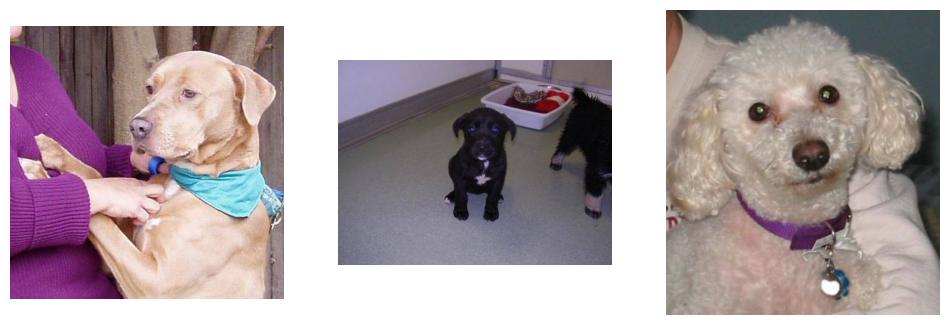

In [7]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1,3, figsize=(12,12))
axes = axes.flatten()
for i, ax in zip(range(3), axes):
    ax.imshow(train_df.iloc[i]['image_data'])
    ax.axis('off')
plt.show()

In [8]:
## Exploratory Data Analysis
print(train_df.shape)
print(train_df['category'].value_counts())

(8005, 2)
category
1    4005
0    4000
Name: count, dtype: int64


The number of cat and dog images are almost equal (Non biased dataset). Since we have only images and category we can go ahead and start training out network, without further EDA.

In [ ]:
## Add a filter
## Add a pooling
## Add padding
## Train a model

In [26]:
class Conv:
    def __init__(self, num_filters = 1):
        self.num_filters = num_filters
        rng = np.random.default_rng()
        self.filters = rng.standard_normal(size = (num_filters, 3, 3))/9
        for filter in self.filters:
            print(filter)

In [ ]:
obj = Conv()

[[ 0.10589567  0.0423446  -0.05957378]
 [-0.01513134 -0.02091314 -0.03168281]
 [ 0.06563302  0.06004603 -0.00266942]]


: 

In [11]:
import torch